In [198]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn.linear_model
from sklearn.datasets import fetch_california_housing

In [199]:
housing = fetch_california_housing(as_frame=True)

In [200]:
print(housing.data.shape, housing.target.shape)

(20640, 8) (20640,)


In [201]:
print(housing.feature_names)

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [202]:
df_all = housing.frame

In [203]:
df_house = df_all.copy()

In [204]:
df_all.to_csv("src/Data_first/housing_raw.csv", index=False)

Dataset not clean is available in Data_first in case i miss something !!

In [205]:
df_house.shape

(20640, 9)

One more features because of the frame function

In [206]:
df_house.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [207]:
df_house.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [208]:
df_house.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [209]:
df_house.duplicated().sum()

np.int64(0)

In [210]:
df_house.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [211]:
print(len(df_house))
df_house = df_house[(df_house["AveRooms"] >= 1) & (df_house["AveOccup"] >= 1)]
print(len(df_house))

20640
20635


5 outliers erased ! 

In [212]:
df_house.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20635.000000,20635.000000,20635.000000,20635.000000,20635.000000,20635.000000,20635.000000,20635.000000,20635.000000
mean,3.871062,28.640611,5.428511,1.096489,1425.805282,3.071064,35.631796,-119.569741,2.068625
std,1.899740,12.585077,2.468694,0.472951,1132.402049,10.387268,2.135885,2.003672,1.153997
min,0.499900,1.000000,1.000000,0.333333,5.000000,1.060606,32.540000,-124.350000,0.149990
25%,2.563800,18.000000,4.440951,1.006111,787.500000,2.430150,33.930000,-121.800000,1.196000
50%,3.535000,29.000000,5.229213,1.048780,1166.000000,2.818444,34.260000,-118.490000,1.797000
75%,4.743700,37.000000,6.052381,1.099514,1725.000000,3.282276,37.710000,-118.010000,2.647500
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [213]:
print((df_house["MedHouseVal"] >= 5).sum())
print((df_house["HouseAge"] >= 52).sum())
print((df_house["MedInc"] >= 15).sum())
print((df_house["MedHouseVal"] <= 0.15).sum())

992
1273
51
4


We want to keep 992 block group of more than 500 000 dollars ? maybe it is useless
We know that the median age is block at 52 for 1273 so the median is maybe more for certain of them no need to chnage that
Only 51 median income around 150 000 dollars, maybe more, they shoudl be correllated with the MedHouseVal higher than 500 000

In [214]:
print(df_house["AveOccup"].nlargest(20))

19006    1243.333333
3364      599.714286
16669     502.461538
13034     230.172414
9172       83.171429
12104      63.750000
16420      51.400000
8874       41.214286
13366      33.952941
5986       21.333333
20352      19.312500
14756      18.821818
4479       18.500000
19435      18.444444
1039       17.177700
16672      16.937500
19524      16.048780
7164       15.812155
15790      15.602941
2511       14.000000
Name: AveOccup, dtype: float64


In [215]:
df_house = df_house[df_house["AveOccup"]<= 20]
print(len(df_house))

20625


its not logical to keep house with more than 20 indiviudal, and that erase only 10 values

In [216]:
print((df_house["AveRooms"] > 20).sum())

68


In [217]:
print(df_house["AveRooms"].nlargest(30))

1914     141.909091
1979     132.533333
12447     62.422222
1913      61.812500
11862     59.875000
1912      56.269231
9676      52.848214
11707     52.690476
2395      50.837838
1240      47.515152
11832     41.333333
11833     39.755906
1872      38.840909
20094     37.063492
1926      37.000000
13950     36.715385
10080     36.478261
11716     36.075472
13965     36.060606
1978      34.843750
9683      34.571429
1239      33.989691
1102      31.777778
3086      31.062500
1024      29.852941
13964     29.248649
2397      29.074766
1234      28.757282
18681     28.600000
13943     28.432143
Name: AveRooms, dtype: float64


In [218]:
df_house = df_house[df_house["AveRooms"] <= 20]

In [219]:
print(df_house["AveBedrms"].nlargest(10))

20113    6.500000
19977    5.263158
3350     5.053030
13980    4.980769
10077    4.740000
9681     4.540146
9682     4.479592
9678     4.432624
10067    4.421875
13923    4.105832
Name: AveBedrms, dtype: float64


OK for AveBedrms nothng to change

In [220]:
print(df_house["Population"].nlargest(10)) 

15360    35682.0
9880     28566.0
13139    16305.0
10309    16122.0
6057     15507.0
6066     15037.0
12215    13251.0
9019     12873.0
17413    12427.0
922      12203.0
Name: Population, dtype: float64


In [221]:
print(df_house.loc[[15360, 9880], ["Population", "AveOccup", "AveRooms", "MedHouseVal"]])

       Population  AveOccup  AveRooms  MedHouseVal
15360     35682.0  7.482072  5.270497        1.344
9880      28566.0  4.696810  5.364518        1.188


No need to erase them 

In [222]:
df_house.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20557.000000,20557.000000,20557.000000,20557.000000,20557.000000,20557.000000,20557.000000,20557.000000,20557.000000
mean,3.871095,28.671499,5.335067,1.077555,1428.113392,2.934633,35.624846,-119.570099,2.069696
std,1.898481,12.577463,1.420830,0.197937,1129.241780,0.865370,2.133095,2.005108,1.154555
min,0.499900,1.000000,1.000000,0.333333,5.000000,1.060606,32.540000,-124.350000,0.149990
25%,2.564300,18.000000,4.438114,1.005894,791.000000,2.431655,33.930000,-121.800000,1.196000
50%,3.535200,29.000000,5.224868,1.048421,1168.000000,2.820423,34.250000,-118.490000,1.798000
75%,4.744000,37.000000,6.041791,1.098710,1727.000000,3.282723,37.710000,-118.010000,2.650000
max,15.000100,52.000000,19.962121,6.500000,35682.000000,19.312500,41.950000,-114.310000,5.000010


In [223]:
print(df_house["HouseAge"].nsmallest(1700))

3130      1.0
12286     1.0
18972     1.0
59        2.0
854       2.0
         ... 
14123    11.0
14188    11.0
14232    11.0
14243    11.0
14356    11.0
Name: HouseAge, Length: 1700, dtype: float64


In [224]:
print(len(df_house))

20557


In [225]:
print(df_house["MedHouseVal"].nsmallest(10))

2521     0.14999
2799     0.14999
9188     0.14999
19802    0.14999
5887     0.17500
1825     0.22500
13889    0.22500
14326    0.22500
16186    0.22500
2779     0.25000
Name: MedHouseVal, dtype: float64


In [226]:
from project_ml.Cleaning import clean_data

df_clean = clean_data(df_all)
print(len(df_clean))

20557


In [227]:
print(len(df_all))

20640


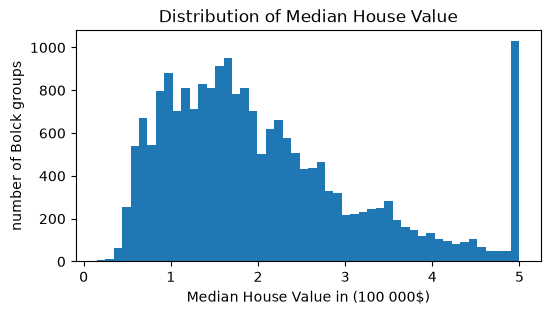

In [228]:
plt.figure(figsize=(6, 3))
plt.hist(df_clean["MedHouseVal"], bins = 50)
plt.xlabel("Median House Value in (100 000$)")
plt.ylabel("number of Bolck groups")
plt.title("Distribution of Median House Value")
plt.show()

We clearly see that a lot of value are block at 500 000 dollars in term of median. we can then imagine that the distriubution is asymetric on the right. The skewness should be really positive. Kurtosis ?? We can also see that a large part of the district are realatively cheap in term of median. A lot of observations are concentrate in a small variance of price in the left and after 200 000 $ in median, the observations of district are more spread

MedHouseVal    1.000000
MedInc         0.689573
AveRooms       0.273879
HouseAge       0.105139
Population    -0.025731
Longitude     -0.045925
AveBedrms     -0.089346
Latitude      -0.143749
AveOccup      -0.241741
Name: MedHouseVal, dtype: float64


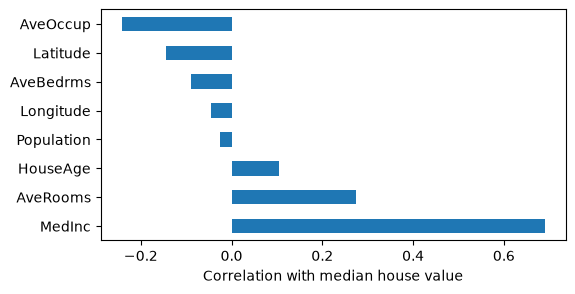

In [229]:
corr_Med = df_clean.corr()["MedHouseVal"].sort_values(ascending=False)
print(corr_Med)
plt.figure(figsize=(6, 3))
corr_Med.drop("MedHouseVal").plot.barh()
plt.xlabel("Correlation with median house value")
plt.show()

The median price per district is relatively positively correlated with the median Income, that's what was expected. The number of rooms and the age of the house is positively correlated, normal because the old cost more than the new.

In contrario Pop, Longitude, Latitude, number of bedrooms and average of people in the district are neagtively correlated, expected except for the average number of bedrooms, it should be the contrario (don't know how to explain that)

In [230]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 20557 entries, 0 to 20556
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20557 non-null  float64
 1   HouseAge     20557 non-null  float64
 2   AveRooms     20557 non-null  float64
 3   AveBedrms    20557 non-null  float64
 4   Population   20557 non-null  float64
 5   AveOccup     20557 non-null  float64
 6   Latitude     20557 non-null  float64
 7   Longitude    20557 non-null  float64
 8   MedHouseVal  20557 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


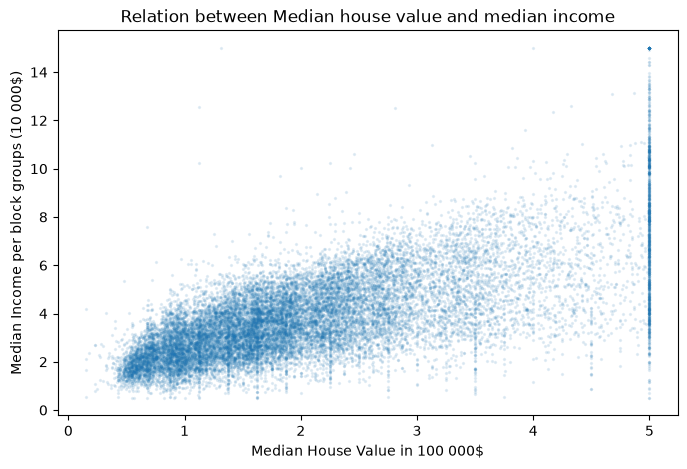

In [231]:
plt.figure(figsize=(8, 5))
plt.scatter(df_clean["MedHouseVal"], df_clean["MedInc"], alpha=0.1, s=2)
plt.xlabel("Median House Value in 100 000$")
plt.ylabel("Median Income per block groups (10 000$)")
plt.title("Relation between Median house value and median income")
plt.show()

That figure show us that as seen previously, we have lot of data blocked at 500 000 $. We can also visualize that the relation between those to variable is positive, as we are in an expensive district, we have a better Income. Also we have to notice that as we increase the Income, as the data are spread

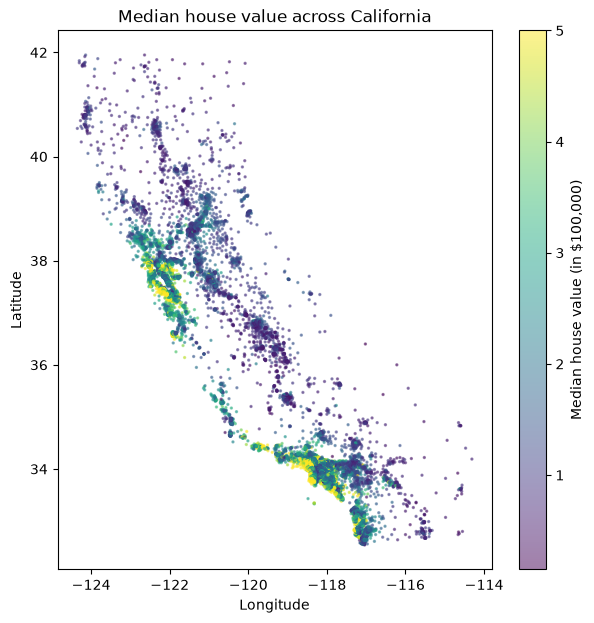

In [232]:
plt.figure(figsize=(7, 7))
plt.scatter(df_clean["Longitude"], df_clean["Latitude"],
            c=df_clean["MedHouseVal"], cmap="viridis", s=2, alpha=0.5)
plt.colorbar(label="Median house value (in $100,000)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Median house value across California")
plt.show()

Here we oberved that as expected the rich neighborhood are located in the center of the Big cities. Los Angeles, San Diego one the south and San Francisco on the north

In [233]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 20557 entries, 0 to 20556
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20557 non-null  float64
 1   HouseAge     20557 non-null  float64
 2   AveRooms     20557 non-null  float64
 3   AveBedrms    20557 non-null  float64
 4   Population   20557 non-null  float64
 5   AveOccup     20557 non-null  float64
 6   Latitude     20557 non-null  float64
 7   Longitude    20557 non-null  float64
 8   MedHouseVal  20557 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


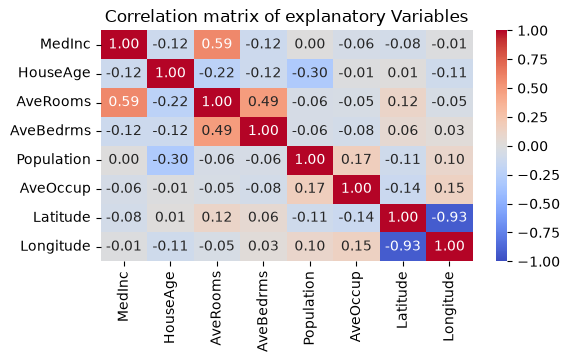

In [234]:
import seaborn as sns

corr_matrix = df_clean.drop(columns="MedHouseVal").corr()

plt.figure(figsize=(6,3))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax =1)
plt.title("Correlation matrix of explanatory Variables")
plt.show()

No variable are too redundant to remove. the max correlation between variable only reach 0.59. Exception for longitude and latitude but it's normal those two variables are going in the complete opposite by definition.

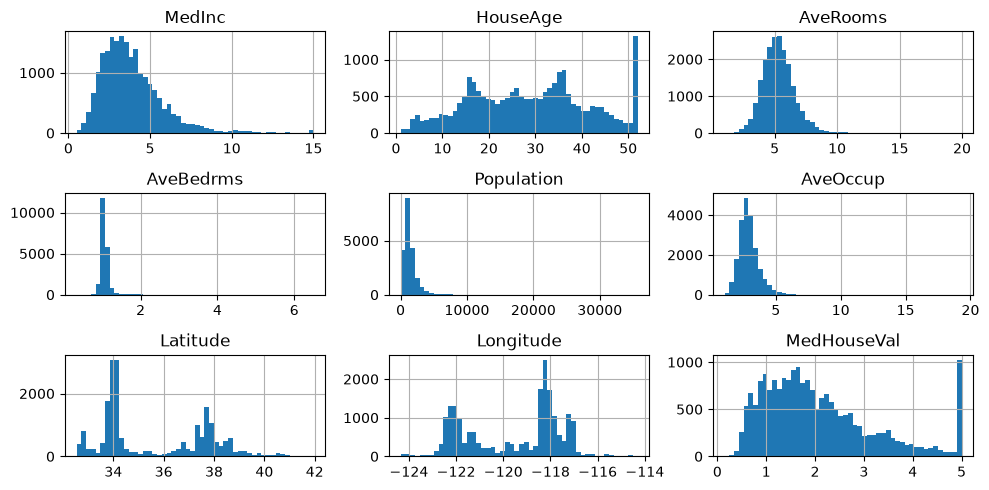

In [235]:
df_clean.hist(bins= 50, figsize=(10,5))
plt.tight_layout()
plt.show()

The clean is done now i will try to do the Rnadom Forest :

In [236]:
print(df_clean.info())

<class 'pandas.DataFrame'>
RangeIndex: 20557 entries, 0 to 20556
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20557 non-null  float64
 1   HouseAge     20557 non-null  float64
 2   AveRooms     20557 non-null  float64
 3   AveBedrms    20557 non-null  float64
 4   Population   20557 non-null  float64
 5   AveOccup     20557 non-null  float64
 6   Latitude     20557 non-null  float64
 7   Longitude    20557 non-null  float64
 8   MedHouseVal  20557 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


In [237]:
print(df_clean.dtypes)

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


In [238]:
columns_num = df_house.select_dtypes(include="number").columns
columns_cat = df_house.select_dtypes(exclude="number").columns
print("Numériques :", list(columns_num))
print("Catégorielles :", list(columns_cat))

Numériques : ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
Catégorielles : []


In [239]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
import time
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn import tree


In [240]:
X = df_clean.drop(["MedHouseVal"], axis=1)
y = df_clean["MedHouseVal"]

print(X.shape)
print(y.shape)

(20557, 8)
(20557,)


In [241]:
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

n_train = 2000

X_train, _, y_train, _ = train_test_split(X_rest, y_rest, train_size=n_train, random_state=123)

print(X_rest.shape, X_train.shape, X_test.shape)

(16445, 8) (2000, 8) (4112, 8)


In [242]:
print(X_rest.shape)

(16445, 8)


2000 obs for the X_train

In [243]:
rf = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1)

for n in [2000, 3000, 4000, 5000, 6000] :
    X_train,_, y_train,_ = train_test_split(X_rest, y_rest, train_size=n, random_state=123)
    start=time.time()
    rf.fit(X_train,y_train)
    duration= time.time() - start
    print(f"{n} rows: {duration:.2f} s per fit -> Jackknife+ ≈ {duration * n / 60:.1f} min")


2000 rows: 0.21 s per fit -> Jackknife+ ≈ 7.0 min
3000 rows: 0.34 s per fit -> Jackknife+ ≈ 16.9 min
4000 rows: 0.30 s per fit -> Jackknife+ ≈ 20.1 min
5000 rows: 0.36 s per fit -> Jackknife+ ≈ 30.2 min
6000 rows: 0.44 s per fit -> Jackknife+ ≈ 44.1 min


The best Trade off here is 5000 rows beacuse it's 45 min to load the chunk not to excessive but with a good part of the data's

In [244]:
n_train = 16000
X_train,_ , y_train,_ = train_test_split(X_rest, y_rest, train_size=n_train, random_state=123)
print(X_train.shape, y_train.shape)



(16000, 8) (16000,)


In [245]:
param_grid = {"max_depth" : [None, 10, 20],
              "min_samples_leaf" : [1, 5, 10],
              "max_features" : [1.0, "sqrt"]}

rf = RandomForestRegressor(n_estimators = 100, random_state=0, n_jobs=-1)
grid_search = GridSearchCV(rf, param_grid, scoring="neg_mean_squared_error", cv=3)
grid_search.fit(X_train, y_train)
print(grid_search.best_params_)



{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1}


In [246]:
final_model = grid_search.best_estimator_

y_pred = final_model.predict(X_test)

print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("R2 :", r2_score(y_test, y_pred))

MSE : 0.235054819795691
RMSE : 0.4848245247465221
MAE : 0.3249768014398904
R2 : 0.8156605423791141


RMSE = 52 500 dollars, mean error around 36 000 dolars and the with a R2 around 0,78, the model explain 78% of the difference price between district. The model is relatively solid! Could be improved, by adding more variables but we need to dicuss that concerning the time on th jacknife 

In [248]:
importance = grid_search.best_estimator_.feature_importances_
print(importance)

[0.34838025 0.05573891 0.12089247 0.04578368 0.03446993 0.12101484
 0.13506246 0.13865746]


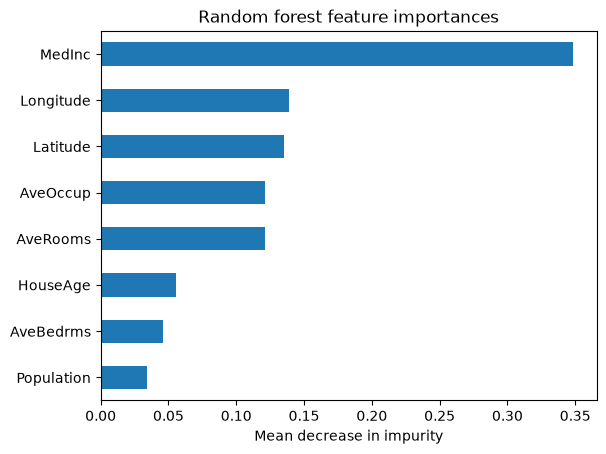

In [247]:
importance = pd.Series(final_model.feature_importances_, index=X_train.columns)
importance.sort_values().plot.barh()
plt.xlabel("Mean decrease in impurity")
plt.title("Random forest feature importances")
plt.savefig("rf_importance.png", dpi=300, bbox_inches="tight")
plt.show()